# Example of the aitlas toolbox in the context of semantic segmentation

This notebook shows a sample implementation of semantic segmentation using the aitlas toolbox. The SpaceNet-7 dataset contains time series images. Each image in the time series is associated to a mask.

## Import the required packages

In [ ]:
from aitlas.datasets import SpaceNet7Dataset
from aitlas.utils import image_loader
from aitlas.models import DeepLabV3
from aitlas.transforms import MinMaxNormTranspose, ResizeToTensor

## Visualize images and masks

In [ ]:
dataset_config = {
    "data_dir" : "./data/spacenet_7/train/",
}
dataset = SpaceNet7Dataset(dataset_config)

print(f"Total number of patches: {len(dataset)}")

Total number of patches: 1423


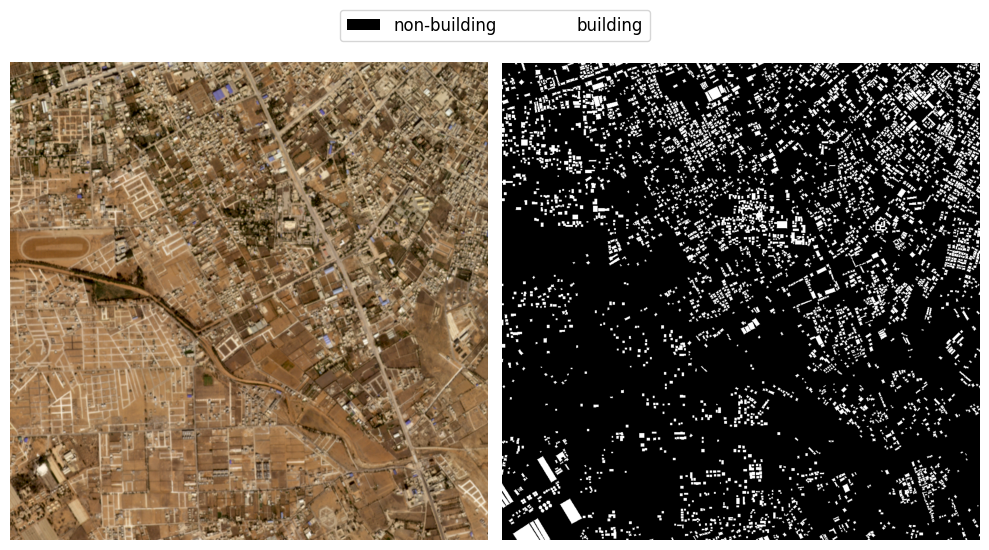

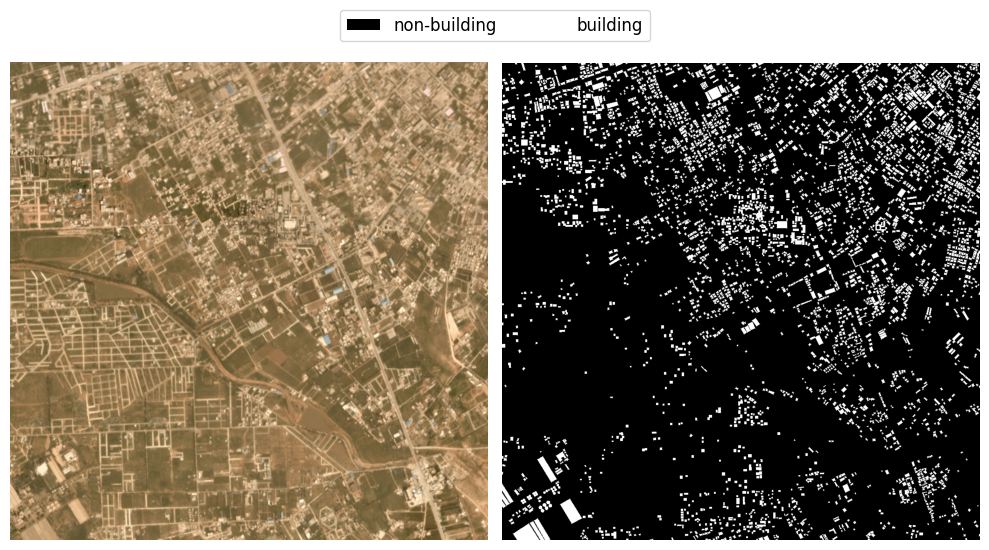

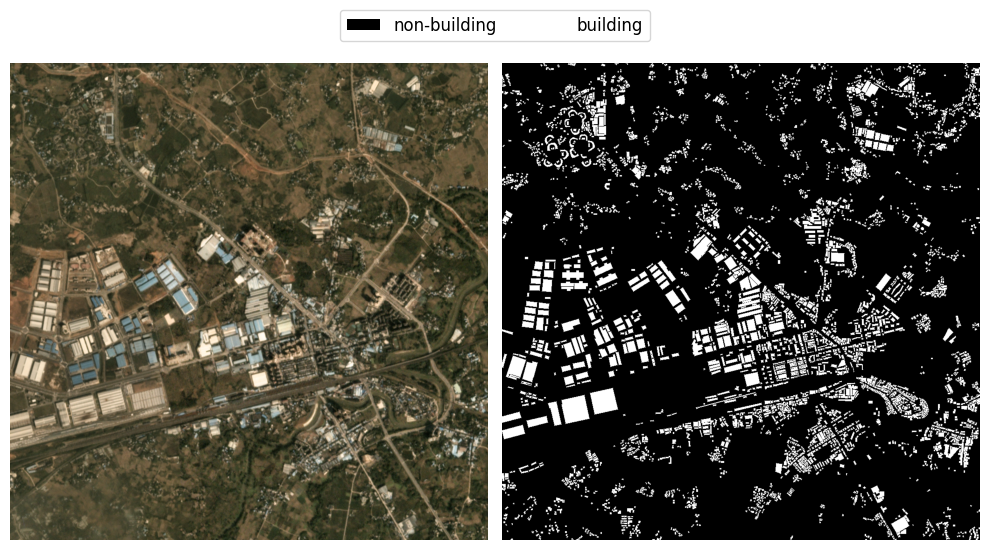

In [59]:
dataset.show_image(15);
dataset.show_image(23);
dataset.show_image(25);

In [63]:
dataset.data_distribution_table()

,Number of pixels
non-building,1.361261e+09
building,1.303756e+08


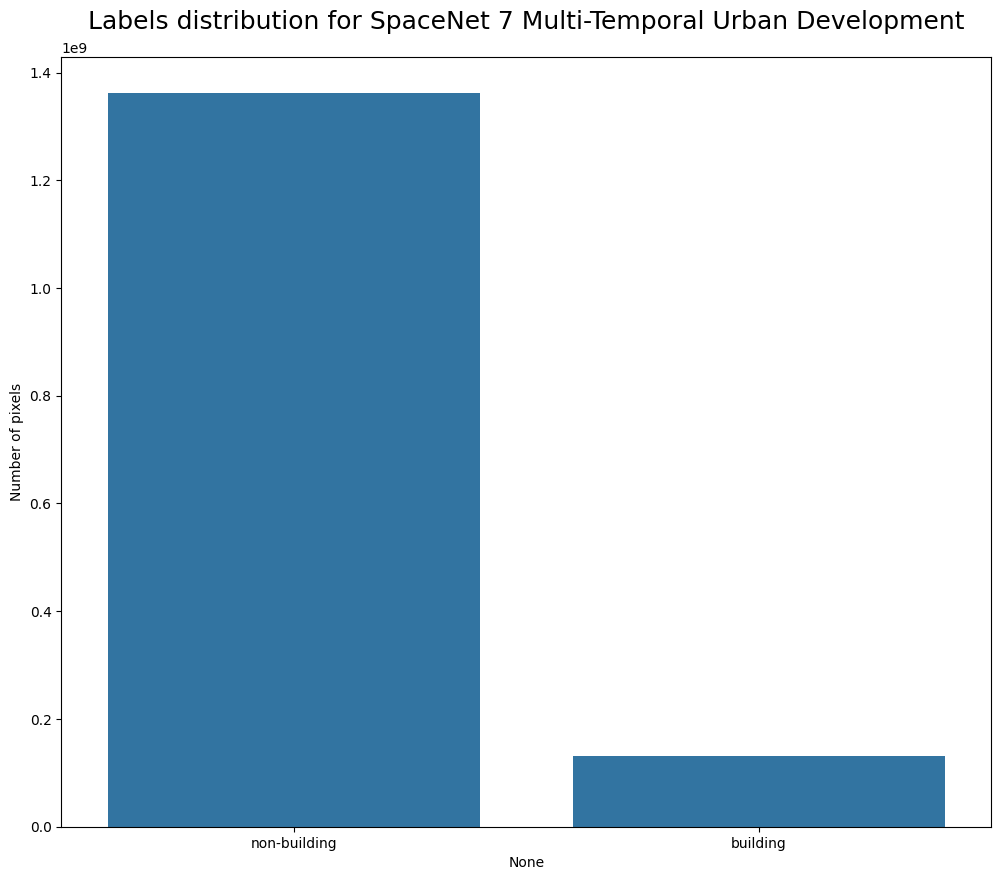

In [64]:
dataset.data_distribution_barchart();

## Load training data ##

In [ ]:
train_dataset_config = {
    "batch_size": 8,
    "shuffle": True,
    "num_workers": 4,
    "data_dir" : "./data/spacenet_7/train/",
    "transforms": ["aitlas.transforms.MinMaxNormTranspose","aitlas.transforms.ResizeToTensor"],
    "target_transforms": ["aitlas.transforms.Transpose","aitlas.transforms.ResizePerChannelToTensor"]
}
train_dataset = SpaceNet7Dataset(train_dataset_config)

len(train_dataset)

1423

## Create the model ##

In [ ]:
epochs = 10
model_directory = "./data/experiments/SpaceNet7"
model_config = {
    "num_classes": 2, 
    "learning_rate": 0.0001,
    "pretrained": True, 
    "threshold": 0.5,
    "metrics": ["iou"]
}

model = DeepLabV3(model_config)
model.prepare()

## Start the training ##

In [72]:
model.train_model(
    train_dataset=train_dataset,
    epochs=epochs,
    model_directory=model_directory,
    run_id='1'
)

2025-10-20 12:17:15,708 INFO Starting training.
training: 100%|██████████| 178/178 [04:41<00:00,  1.58s/it]
2025-10-20 12:21:57,729 INFO epoch: 1, time: 282, loss:  0.34287
testing on train set: 100%|██████████| 178/178 [04:34<00:00,  1.54s/it]
2025-10-20 12:26:34,118 INFO IOU:0.34573646577958744, IOU mean:0.35060423028226745, IOU per Class:[0.69590949 0.00529897]
training: 100%|██████████| 178/178 [04:37<00:00,  1.56s/it]
2025-10-20 12:31:11,917 INFO epoch: 2, time: 277, loss:  0.22097
testing on train set: 100%|██████████| 178/178 [04:31<00:00,  1.52s/it]
2025-10-20 12:35:43,170 INFO IOU:0.000539754787939648, IOU mean:0.0002718019245945968, IOU per Class:[0.0005436 0.       ]
training: 100%|██████████| 178/178 [04:31<00:00,  1.53s/it]
2025-10-20 12:40:14,670 INFO epoch: 3, time: 271, loss:  0.13884
testing on train set: 100%|██████████| 178/178 [04:40<00:00,  1.58s/it]
2025-10-20 12:44:55,479 INFO IOU:0.738378104679956, IOU mean:0.3711460462376991, IOU per Class:[0.74229209 0.       

0.08998777836205167

## Predictions ##

2025-10-20 13:50:29,793 INFO Loading checkpoint /home/dragik/data/FAIR_EO/experiments/SpaceNet7/checkpoint.pth.tar
2025-10-20 13:50:30,216 INFO Loaded checkpoint /home/dragik/data/FAIR_EO/experiments/SpaceNet7/checkpoint.pth.tar at epoch 11


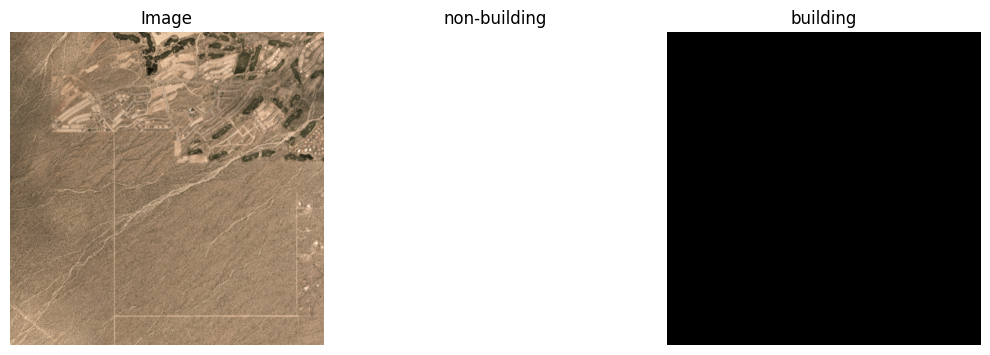

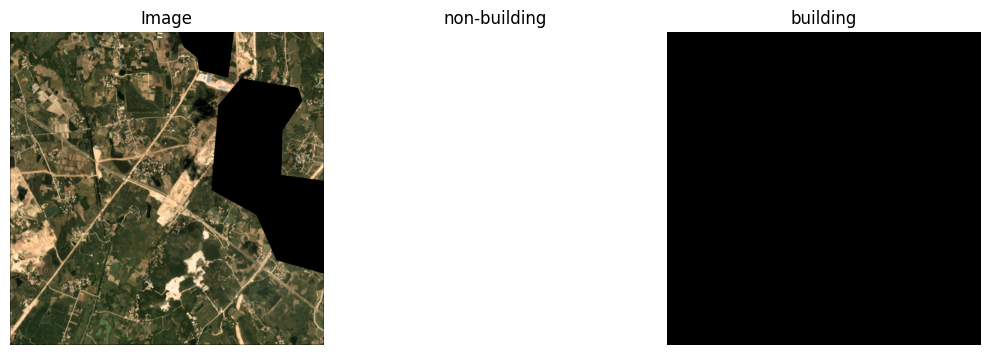

In [ ]:
model_path = "./data/experiments/SpaceNet7/checkpoint.pth.tar"
labels = ["non-building","building"]
transform = ResizeToTensor()
model.load_model(model_path)

image = image_loader('./data/spacenet_7/test_public/L15-0391E-1219N_1567_3314_13/images_masked/global_monthly_2018_03_mosaic_L15-0391E-1219N_1567_3314_13.tif')[:,:,:3]
fig = model.predict_masks(image, labels, transform)
image = image_loader('./data/spacenet_7/test_public/L15-1690E-1210N_6762_3348_13/images_masked/global_monthly_2018_07_mosaic_L15-1690E-1210N_6762_3348_13.tif')[:,:,:3]
fig = model.predict_masks(image, labels, transform)